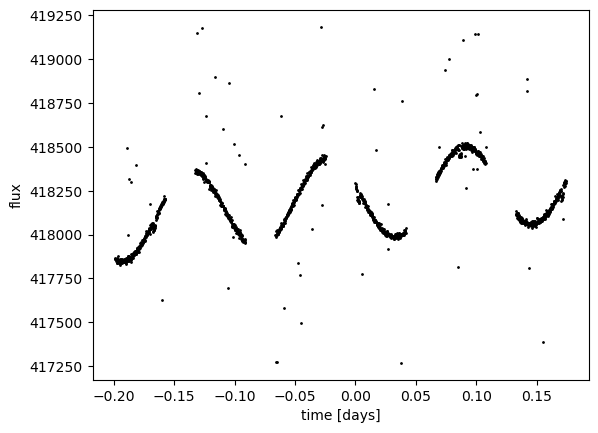

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Load the data
dataraw = np.loadtxt('data_headers.dat', skiprows=3, unpack=True)   
data = dataraw

tpivot = np.median(data[0][:])    # pivot point for later
data = np.stack((dataraw[0][:]-tpivot,dataraw[1][:],dataraw[2][:]))

time=data[0][:]   
flux=data[1][:]     
fluxerr=data[2][:]  

# Some information we know
mins = 1.0/(24.0*60.0)       # one minute (days)
Phst = 95.48*mins            # period of HST
dur = 166.484/86400.0        # duration of the eclipse 
t0 = 57531.91792371155       # mid-time of first eclipse
Ptran = 0.08437610463121233  # period of eclipses 
cadence = 13.2/86400.0       # cadence 

%matplotlib inline

plt.scatter(time, flux, color='k', s=1)
plt.xlabel('time [days]')
plt.ylabel('flux')
plt.show()

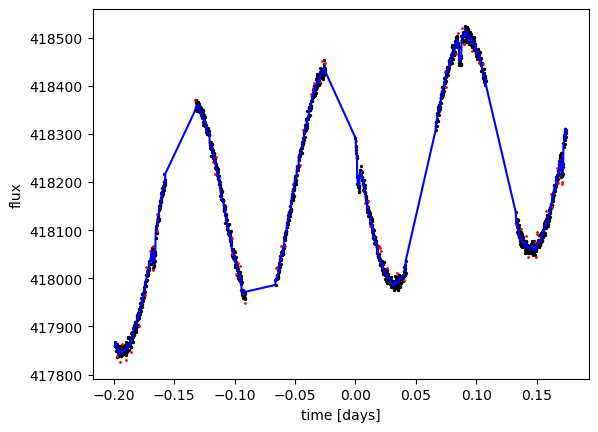

4.964075767472241 % of the original data is an outlier


In [40]:
# TASK 1: REMOVE OUTLIERS

# Define a moving median function
def movingmedian(x,window):
    n = len(x) - window + 1
    out = np.zeros(n)
    for i in range(n):
        out[i] = np.median(x[i:i+window])
    return out

# Calculate moving medians
smoothwindow = 11
timesmooth = movingmedian(time,smoothwindow)
fluxsmooth = movingmedian(flux,smoothwindow)

# Append the edges of the windows
h = (smoothwindow-1)//2
timesmooth = np.concatenate((time[:h], timesmooth, time[-h:]))
fluxsmooth = np.concatenate((flux[:h], fluxsmooth, flux[-h:]))
fluxpred = fluxsmooth

# Split data into good vs bad
sigmas = 2
data2 = np.zeros((2,3))      # 2 dummy rows, trimmed off below
baddata = np.zeros((2,3))
for i in range(len(flux)):
    row = np.array([[time[i], flux[i], fluxerr[i]]])
    if abs(flux[i] - fluxpred[i]) < sigmas*fluxerr[i]:
        data2 = np.vstack((data2, row))
    else:
        baddata = np.vstack((baddata, row))
data2=data2[2:,:]
baddata=baddata[2:,:]

%matplotlib inline

plt.scatter(data2[:,0], data2[:,1], color='black', s=2)
plt.plot(time, fluxpred, color='blue')
plt.scatter(baddata[:,0], baddata[:,1], color='r', s=1)
plt.xlabel('time [days]')
plt.ylabel('flux')
plt.show()
print(100.0*len(baddata)/len(flux),'% of the original data is an outlier')

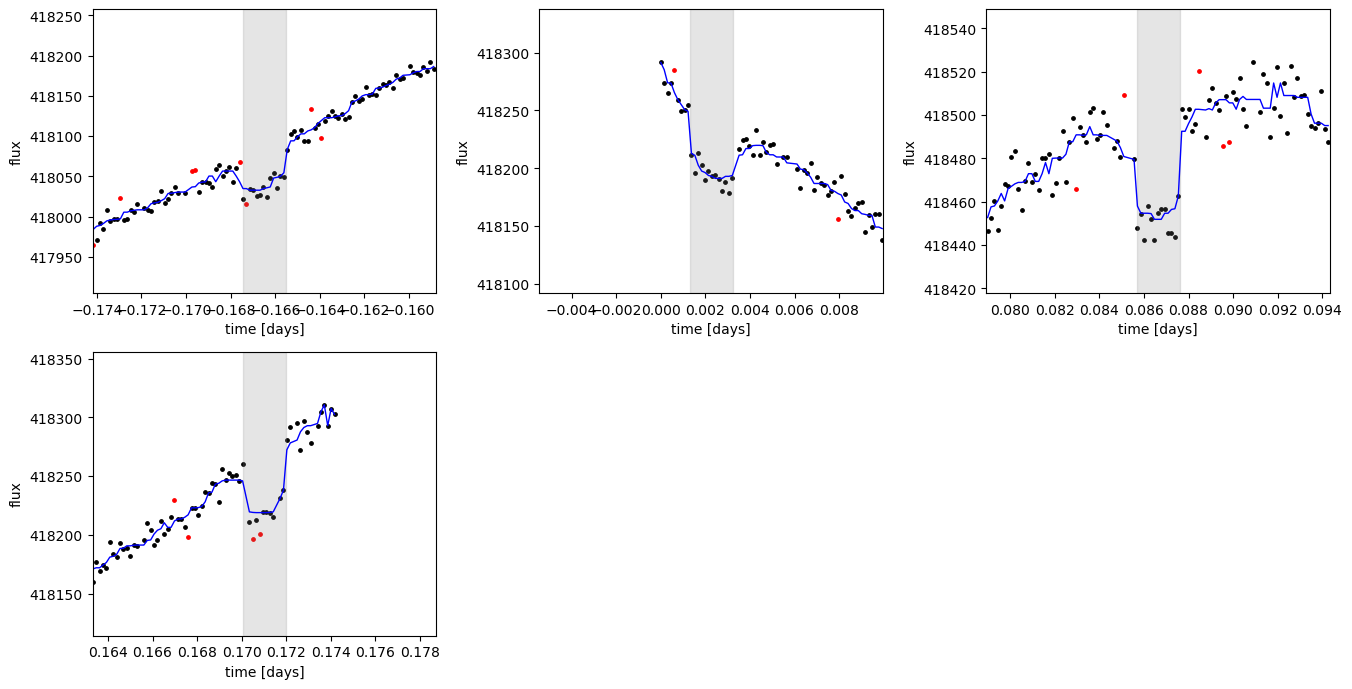

In [41]:
%matplotlib inline

# Zoom in on each transit
t_mid = t0 - tpivot
n_all = np.arange(np.floor((time.min()-t_mid)/Ptran), np.ceil((time.max()-t_mid)/Ptran)+1)
centres = t_mid + n_all*Ptran
half = 4.0*dur   # half-width of each zoom window
centres = [tc for tc in centres if np.sum(np.abs(data2[:,0]-tc) < half) > 5]   # skip transits with no data

ncols = 3
nrows = int(np.ceil(len(centres)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.5*nrows), squeeze=False)
for ax, tc in zip(axes.flat, centres):
    g = np.abs(data2[:,0]-tc) < half
    b = np.abs(baddata[:,0]-tc) < half
    f = np.abs(time-tc) < half
    ax.scatter(data2[g,0], data2[g,1], color='k', s=6)
    ax.plot(time[f], fluxpred[f], color='b', lw=1)
    ax.scatter(baddata[b,0], baddata[b,1], color='r', s=6)
    ax.axvspan(tc-dur/2, tc+dur/2, color='grey', alpha=0.2)   # expected transit duration
    lo, hi = data2[g,1].min(), data2[g,1].max()
    pad = 0.3*(hi-lo)
    ax.set_xlim(tc-half, tc+half)
    ax.set_ylim(lo-pad, hi+pad)
    ax.set_xlabel('time [days]')
    ax.set_ylabel('flux')
for ax in axes.flat[len(centres):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

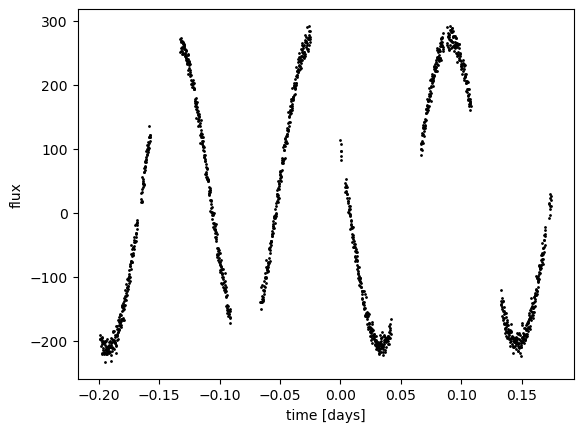

In [8]:
# TASK 2: FIND THE SINUSOIDAL SIGNAL's PERIOD

# removing transits first
timefold2 = data2[:,0] - (t0-tpivot) - Ptran*np.round( (data2[:,0] - (t0-tpivot))/Ptran ) # time since the nearest mid-eclipse

# Keep only points outside the eclipse 
padding = 0.75*dur
data3 = data2[np.abs(timefold2) > padding, :]   

# Task 2b: Remove a linear trend first, before passing through to periodogram
tempslope = np.polyfit(data3[:,0], data3[:,1], 1)
periodogramdata = data3[:,1] - ( tempslope[1] + tempslope[0]*data3[:,0] )

%matplotlib inline

plt.scatter(data3[:,0], periodogramdata, color='k', s=1)
plt.xlabel('time [days]')
plt.ylabel('flux')
plt.show()

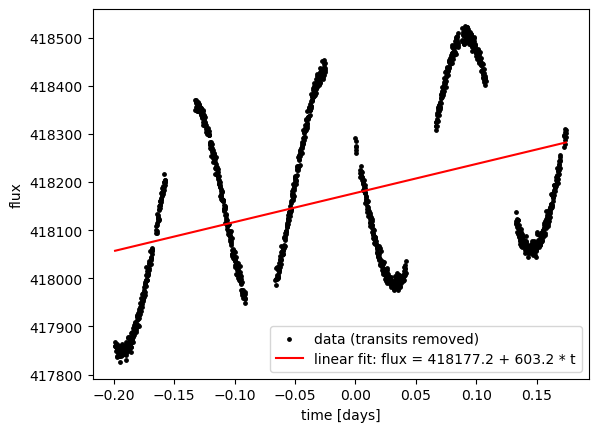

In [9]:
%matplotlib inline

# Linear fit from 2b
linearfit = tempslope[1] + tempslope[0]*data3[:,0]

plt.scatter(data3[:,0], data3[:,1], color='k', s=6, label='data (transits removed)')
plt.plot(data3[:,0], linearfit, color='r',
         label='linear fit: flux = %.1f + %.1f * t' % (tempslope[1], tempslope[0]))
plt.xlabel('time [days]')
plt.ylabel('flux')
plt.legend()
plt.show()

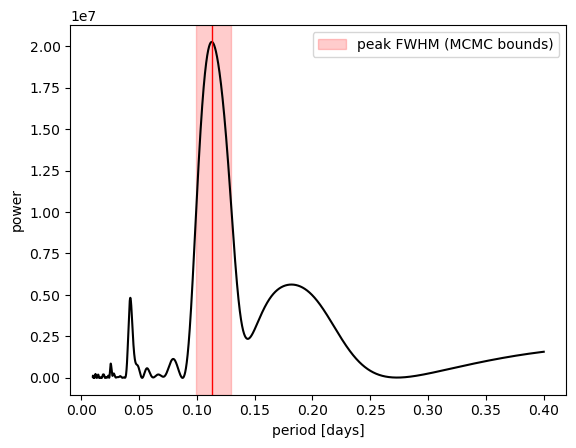

best period =  0.11286845736914738
best amp =  235.46203928841743
peak FWHM = 0.03051 d  ->  MCMC period bounds: 0.09941 < P < 0.12992


In [11]:
# Task 2c: Now run a periodogram through it
import scipy.signal as signal

nfreq = 50000
Pmin = 0.01   
Pmax = 0.4     
periods = np.linspace(Pmin, Pmax, nfreq)
freqs = 2.0*np.pi/periods    #angular frequencies

pgram = signal.lombscargle(data3[:,0], periodogramdata, freqs)
Pbest = periods[np.argmax(pgram)]
Abest = np.sqrt(4.0*pgram[np.argmax(pgram)]/len(data3[:,0]))

# Width of the tallest peak and FWHM
ipeak = np.argmax(pgram)
halfmax = 0.5*pgram[ipeak]
ilo = ipeak
while ilo > 0 and pgram[ilo] > halfmax:
    ilo -= 1
ihi = ipeak
while ihi < len(pgram)-1 and pgram[ihi] > halfmax:
    ihi += 1
Plo, Phi = periods[ilo], periods[ihi]
Pwidth = Phi - Plo

%matplotlib inline

plt.plot(periods, pgram, color='k')
plt.axvspan(Plo, Phi, color='r', alpha=0.2, label='peak FWHM (MCMC bounds)')
plt.axvline(Pbest, color='r', lw=1)
plt.xlabel('period [days]')
plt.ylabel('power')
plt.legend(loc='upper right')
plt.show()

print('best period = ', Pbest)
print('best amp = ', Abest)
print('peak FWHM = %.5f d  ->  MCMC period bounds: %.5f < P < %.5f' % (Pwidth, Plo, Phi))

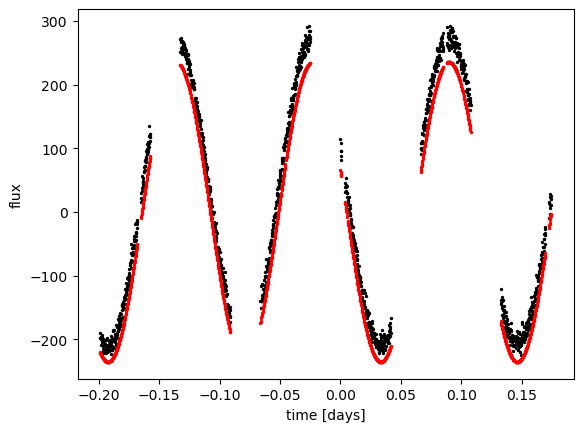

In [12]:
# TASK 3: REMOVE THE SINUSOID + TREND
# Task 3a: Start by plotting our the vanilla sinusoid and manually tune the phase

# hand tuned phase
phase = 2.86
period = 0.11286845736914738 #Pbest
amp = 235.46203928841743 #Abest

fittedsinudoid = amp*np.sin( 2.0*np.pi*data3[:,0]/period + phase )   

%matplotlib inline

plt.scatter(data3[:,0], periodogramdata, color='k', s=2)
plt.scatter(data3[:,0], fittedsinudoid, color='r', s=2)
plt.xlabel('time [days]')
plt.ylabel('flux')
plt.show()

In [13]:
# TASK 3: REMOVE THE SINUSOID + A LINEAR TREND TOGETHER MCMC

time=data3[:,0]     
flux=data3[:,1]    
fluxerr=data3[:,2] 

# Define the model
def model(t,theta):
    a0, a1, A, P, phi = theta
    modflux = a0 + a1*t + A*np.sin(2.0*np.pi*t/P + phi)
    return modflux

# Prior on the period from periodogram
def log_prior(theta):
    P = theta[3]
    if Plo < P < Phi:
        return 0.0
    return -np.inf

# loglikelihood assuming normally distributed data
def log_like(t,f,ferr,theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    modflux = model(t,theta)
    loglike = lp - 0.5*np.sum(((f - modflux)/ferr)**2)
    return loglike

# Set an initial chain point, seed from a "reasonable" solution
#thetachain = np.array([[tempslope[1], tempslope[0], Abest, Pbest, 3.0]])
thetachain = np.array([[418000, 500, 200, 0.1, 3.0]])

# Calculate modified loglike
loglikechain = np.array([log_like(time, flux, fluxerr, thetachain[0])])
assert np.isfinite(loglikechain[0]), 'initial period is outside the periodogram-peak bounds (Plo, Phi)'

In [14]:
# Define the proposal jump size
a0jump = 0.1*np.median(fluxerr) #intercept
aljump = 0.1*np.median(fluxerr)/(np.amax(time) - np.amin(time)) #drift slope
Ajump = 0.1*np.median(fluxerr) #sinusoid amplitude
Pjump = 0.005*Pbest #sinusoid period
phijump = 2.0*np.pi/1000.0 #sinusoid phase
thetajump=np.array([a0jump,aljump,\
                    Ajump,Pjump,phijump])

# Starting walking
j=0
jmax=100
while True:

    # Generate proposal
    thetaprop = thetachain[j] + thetajump*np.random.randn(5)
    loglikeprop = log_like(time, flux, fluxerr, thetaprop)

    # Compute Metropolis Rule
    if loglikeprop - loglikechain[j] > np.log(np.random.rand()):
        # accept
        thetachain = np.vstack((thetachain, thetaprop))
        loglikechain = np.append(loglikechain, loglikeprop)
    else:
        # reject
        thetachain = np.vstack((thetachain, thetachain[j]))
        loglikechain = np.append(loglikechain, loglikechain[j])
    j = j+1

    if j==jmax:
        break

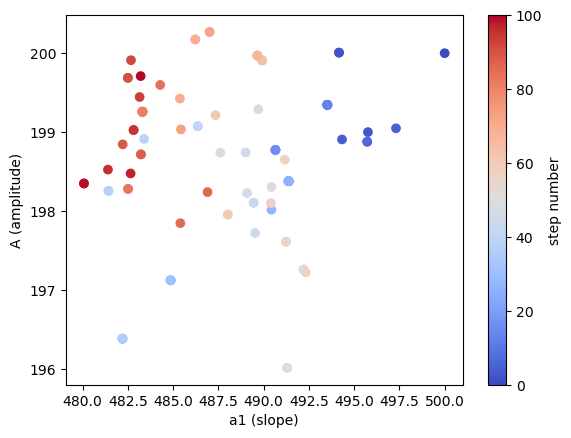

In [15]:
%matplotlib inline

jlist=np.arange(len(thetachain))
plt.scatter(thetachain[:,1], thetachain[:,2], c=jlist, cmap='coolwarm')
plt.colorbar(label='step number')
plt.xlabel('a1 (slope)')
plt.ylabel('A (amplitude)')
plt.show()

In [16]:
# See what the standard deviation of the second half of the initial MCMC chain was...
thetavar=[np.std(thetachain[50:jmax,0]),np.std(thetachain[50:jmax,1]),np.std(thetachain[50:jmax,2]),\
np.std(thetachain[50:jmax,3]),np.std(thetachain[50:jmax,4])]
print('Check that polynomial coeff jump params are ~less than stdevs...')
print(thetavar[0],thetavar[1])
print(thetajump[0],thetajump[1])
print(' ')
print('Check that sinusoidal coeff jump params are ~less than stdevs...')
print(thetavar[2],thetavar[3],thetavar[4])
print(thetajump[2],thetajump[3],thetajump[4])

Check that polynomial coeff jump params are ~less than stdevs...
4.632349999929776 3.6225014119558216
0.8864388000000001 2.3759807013707985
 
Check that sinusoidal coeff jump params are ~less than stdevs...
1.0182354281293489 0.0017217632039645255 0.012091701142721484
0.8864388000000001 0.000564342286845737 0.006283185307179587


In [17]:
# Restart the chain
thetajump = 0.5*np.array(thetavar)

# Starting walking
j=100
jmax=1000
while True:

    # Generate a proposal
    thetaprop = thetachain[j] + thetajump*np.random.randn(5)
    loglikeprop = log_like(time, flux, fluxerr, thetaprop)

    # Compute Metropolis Rule
    if loglikeprop - loglikechain[j] > np.log(np.random.rand()):
        thetachain = np.vstack((thetachain, thetaprop))
        loglikechain = np.append(loglikechain, loglikeprop)
    else:
        thetachain = np.vstack((thetachain, thetachain[j]))
        loglikechain = np.append(loglikechain, loglikechain[j])
    j = j+1

    if j==jmax:
        break

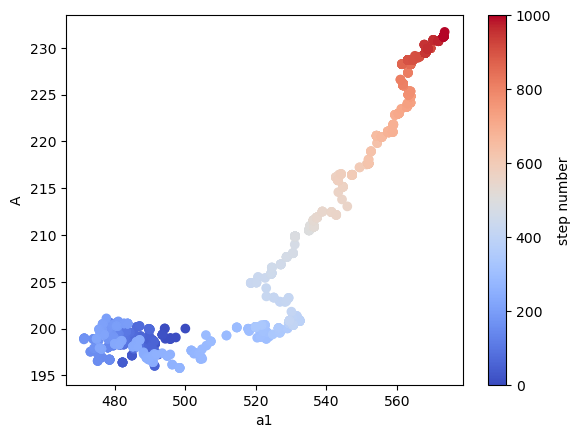

In [18]:
# Medium-run plot
%matplotlib inline

jlist=np.arange(len(thetachain))
plt.scatter(thetachain[:,1], thetachain[:,2], c=jlist, cmap='coolwarm')
plt.colorbar(label='step number')
plt.xlabel('a1')
plt.ylabel('A')
plt.show()

In [19]:
# Starting walking
j=1000
jmax=10000
while True:

    # Generate a proposal (or jump)
    thetaprop = thetachain[j] + thetajump*np.random.randn(5)
    loglikeprop = log_like(time, flux, fluxerr, thetaprop)

    # Compute Metropolis Rule
    if loglikeprop - loglikechain[j] > np.log(np.random.rand()):
        thetachain = np.vstack((thetachain, thetaprop))
        loglikechain = np.append(loglikechain, loglikeprop)
    else:
        thetachain = np.vstack((thetachain, thetachain[j]))
        loglikechain = np.append(loglikechain, loglikechain[j])
    j = j+1

    if j==jmax:
        break

In [20]:
# Trim the frozen tail
last = np.where(np.any(np.diff(thetachain, axis=0) != 0, axis=1))[0][-1] + 1
thetachain = thetachain[:last+1]
loglikechain = loglikechain[:last+1]

# Jumps matched to the posterior widths [a0, a1, A, P, phi]
thetajump = 0.5*np.array([0.24, 2.15, 0.33, 2.8e-5, 1.5e-3])

# Continue walking from the end of the trimmed chain
j = len(thetachain) - 1
jmax = j + 10000
while True:

    thetaprop = thetachain[j] + thetajump*np.random.randn(5)
    loglikeprop = log_like(time, flux, fluxerr, thetaprop)

    if loglikeprop - loglikechain[j] > np.log(np.random.rand()):
        thetachain = np.vstack((thetachain, thetaprop))
        loglikechain = np.append(loglikechain, loglikeprop)
    else:
        thetachain = np.vstack((thetachain, thetachain[j]))
        loglikechain = np.append(loglikechain, loglikechain[j])
    j = j+1

    if j==jmax:
        break

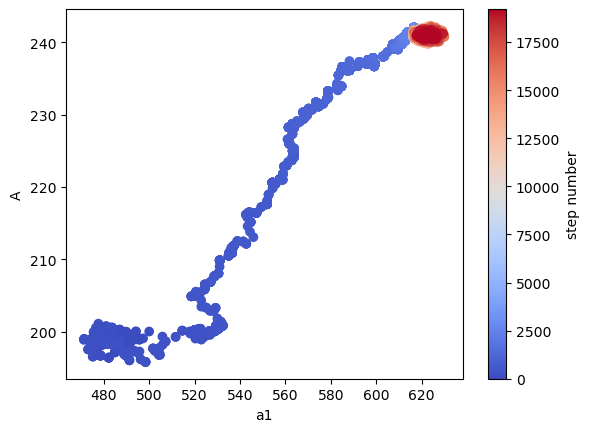

In [21]:
%matplotlib inline

jlist=np.arange(len(thetachain))
plt.scatter(thetachain[:,1], thetachain[:,2], c=jlist, cmap='coolwarm')
plt.colorbar(label='step number')
plt.xlabel('a1')
plt.ylabel('A')
plt.show()

In [22]:
loglikeburn=np.median(loglikechain)
j=-1
while True:
    j=j+1
    if loglikechain[j] > loglikeburn:
        break
burnj=j
print('Burn point = ',burnj)

Burn point =  9211


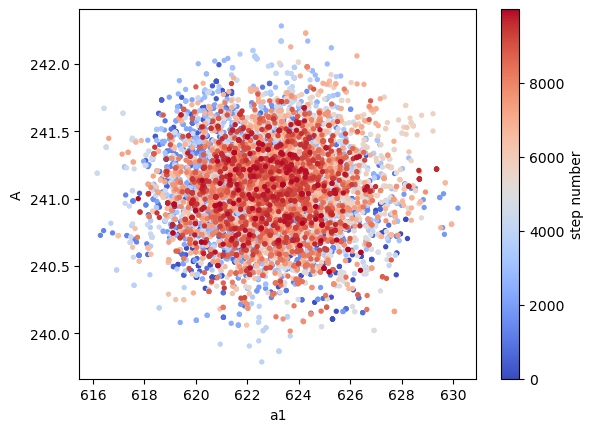

In [23]:
%matplotlib inline

thetachainburnt=thetachain[burnj:,:]
loglikechainburnt=loglikechain[burnj:]

jlist=np.arange(len(thetachainburnt))
plt.scatter(thetachainburnt[:,1], thetachainburnt[:,2], c=jlist, cmap='coolwarm', s=8)
plt.colorbar(label='step number')
plt.xlabel('a1')
plt.ylabel('A')
plt.show()

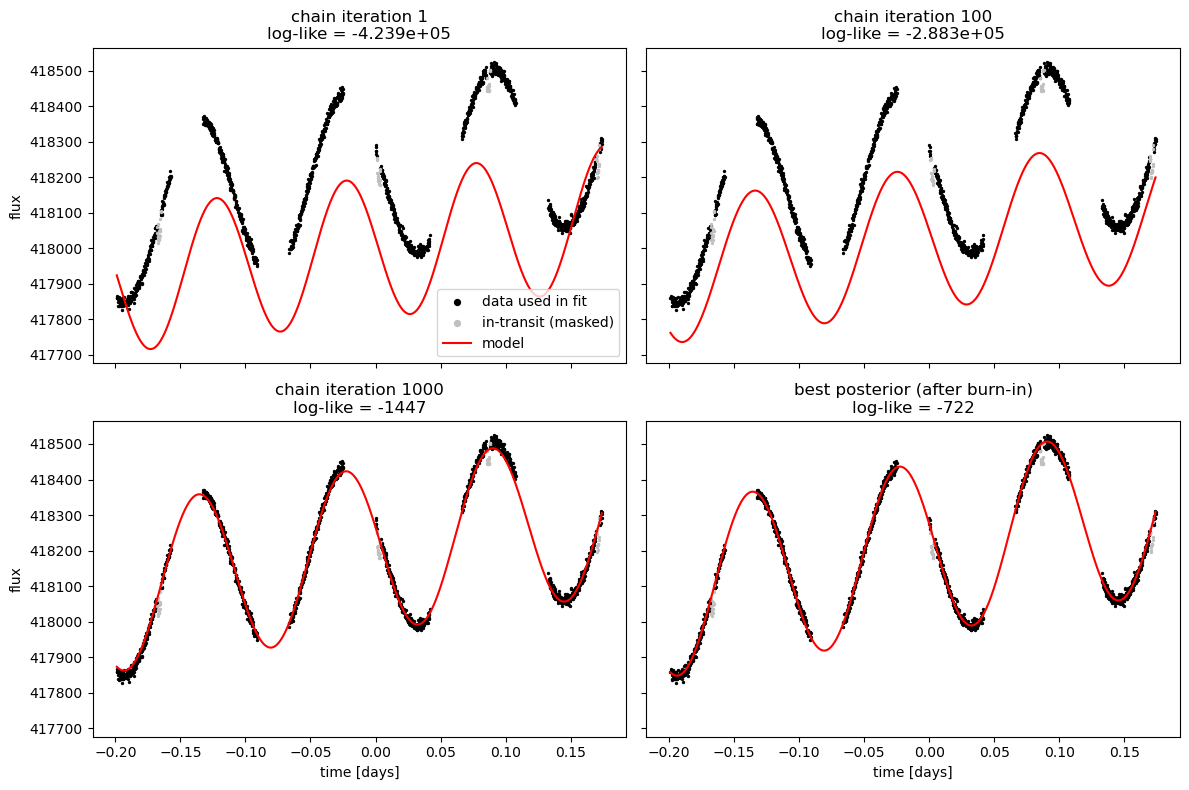

In [24]:
thetabest=thetachainburnt[np.argmax(loglikechainburnt),:]
densetimes=np.arange(data2[0,0],data2[len(data2)-1,0],cadence)
densemodel=model(densetimes,thetabest)

%matplotlib inline

# Model vs data at chain iterations 1, 100, 1000 and at the best posterior point
panels = [('chain iteration 1',    thetachain[1],    loglikechain[1]),
          ('chain iteration 100',  thetachain[100],  loglikechain[100]),
          ('chain iteration 1000', thetachain[1000], loglikechain[1000]),
          ('best posterior (after burn-in)', thetabest, loglikechainburnt.max())]

masked = ~np.isin(data2[:,0], data3[:,0])      # in-transit points, left out of the trend + sinusoid fit

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (title, th, ll) in zip(axes.flat, panels):
    ax.scatter(data3[:,0], data3[:,1], color='k', s=2, label='data used in fit')
    ax.scatter(data2[masked,0], data2[masked,1], color='silver', s=2, label='in-transit (masked)')
    ax.plot(densetimes, model(densetimes, th), color='r', lw=1.5, label='model')
    ax.set_title('%s\nlog-like = %.4g' % (title, ll))
for ax in axes[1,:]:
    ax.set_xlabel('time [days]')
for ax in axes[:,0]:
    ax.set_ylabel('flux')
axes[0,0].legend(loc='lower right', markerscale=3)
plt.tight_layout()
plt.show()


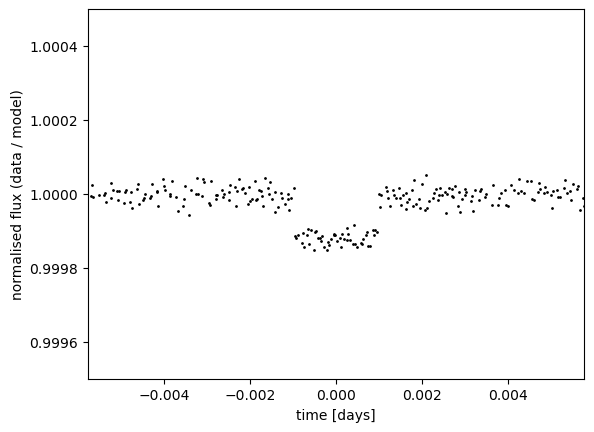

In [25]:
# TASK 4: NOW CO-ADD THE TRANSITS TO GET DEPTH

time = data2[:,0]
flux = data2[:,1]
fluxerr = data2[:,2]

# Divide and normalize
modelflux = model(time, thetabest)
norm = flux/modelflux
normerr = fluxerr/modelflux  

timefold = np.zeros(len(time))
for i in range(len(time)):
    timefold[i] = time[i] - (t0-tpivot) - Ptran*round( ( time[i] - (t0-tpivot) )/Ptran )   # highlighted on the slide

%matplotlib inline

plt.scatter(timefold, norm, color='k', s=1)
plt.axis([-3.0*dur, 3.0*dur, 1.0-0.0005, 1.0+0.0005])
plt.ticklabel_format(useOffset=False, axis='y')
plt.xlabel('time [days]')
plt.ylabel('normalised flux (data / model)')
plt.show()

In [26]:
# Split the folded points
intransit = np.abs(timefold) < dur/2.0
outtransit = np.abs(timefold) >= dur/2.0

# Weighted mean and its error
def weighted_mean(F, Ferr):
    w = 1.0/Ferr**2
    return np.sum(w*F)/np.sum(w), 1.0/np.sqrt(np.sum(w))

# Depth from F_in and F_out
def measure_depth(F, Ferr, intr, outr):
    F_in, sig_in = weighted_mean(F[intr], Ferr[intr])
    F_out, sig_out = weighted_mean(F[outr], Ferr[outr])
    ratio = F_in/F_out
    depth = 1.0 - ratio
    deptherr = ratio*np.sqrt((sig_in/F_in)**2 + (sig_out/F_out)**2)
    return depth, deptherr, F_in, F_out, sig_in, sig_out

depth, deptherr, F_in, F_out, sig_in, sig_out = measure_depth(norm, normerr, intransit, outtransit)

print('F_in  = %.7f +/- %.1e' % (F_in, sig_in))
print('F_out = %.7f +/- %.1e' % (F_out, sig_out))
print('Depth = ', depth, '+/-', deptherr)


F_in  = 0.9998800 +/- 3.0e-06
F_out = 0.9999998 +/- 5.5e-07
Depth =  0.00011983641951973656 +/- 3.07719000530204e-06


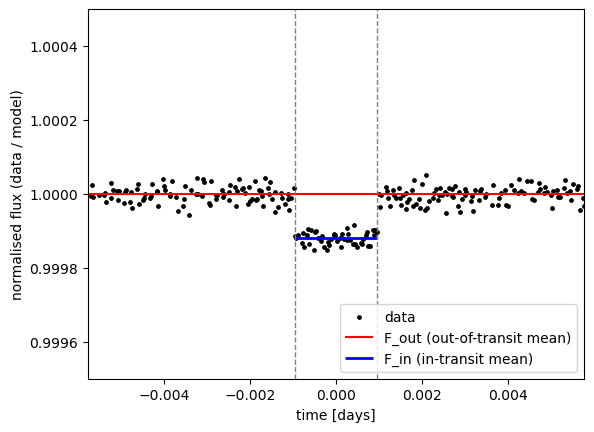

In [27]:
%matplotlib inline

plt.scatter(timefold, norm, color='k', s=6, label='data')

# F_out across the whole window, F_in across the transit only
plt.hlines(F_out, -3.0*dur, 3.0*dur, color='r', label='F_out (out-of-transit mean)')
plt.hlines(F_in, -dur/2.0, dur/2.0, color='b', lw=2, label='F_in (in-transit mean)')

# Mark the transit edges and the depth itself
plt.axvline(-dur/2.0, color='grey', ls='--', lw=1)
plt.axvline(dur/2.0, color='grey', ls='--', lw=1)
plt.axis([-3.0*dur, 3.0*dur, 1.0-0.0005, 1.0+0.0005])
plt.ticklabel_format(useOffset=False, axis='y')
plt.xlabel('time [days]')
plt.ylabel('normalised flux (data / model)')
plt.legend(loc='lower right')
plt.show()

transit 0: 13 in-transit pts, depth = 1.121e-04 +/- 6.5e-06
transit 2: 13 in-transit pts, depth = 1.242e-04 +/- 6.9e-06
transit 3: 13 in-transit pts, depth = 1.170e-04 +/- 6.5e-06
transit 4: 10 in-transit pts, depth = 1.202e-04 +/- 7.4e-06
Weighted average of individual depths = 1.181e-04 +/- 3.4e-06
chi2 = 1.75 for 4 transits (dof = 3)
co-added depth = 1.198e-04 +/- 3.1e-06


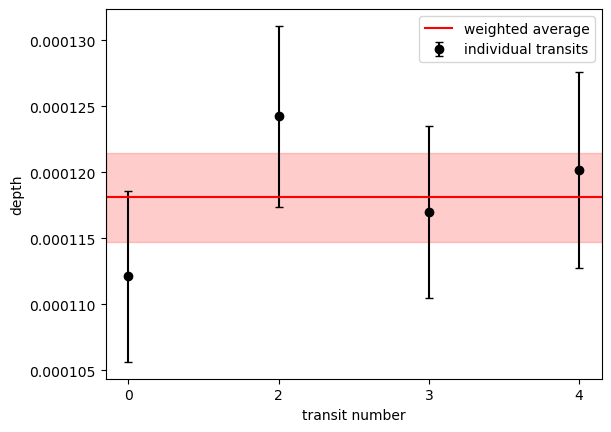

In [28]:
# Individual transit depths
epoch = np.round((time - (t0-tpivot))/Ptran)     
window = 3.0*dur                                 

depths, deptherrs, epochs_used = [], [], []
for n in np.unique(epoch):
    this = (epoch == n)
    intr = this & (np.abs(timefold) < dur/2.0)
    outr = this & (np.abs(timefold) >= dur/2.0) & (np.abs(timefold) < window)
    if intr.sum() < 3 or outr.sum() < 3:         
        continue
    d, de = measure_depth(norm, normerr, intr, outr)[:2]
    depths.append(d)
    deptherrs.append(de)
    epochs_used.append(int(n))
    print('transit %d: %d in-transit pts, depth = %.3e +/- %.1e' % (n, intr.sum(), depths[-1], deptherrs[-1]))

depths, deptherrs = np.array(depths), np.array(deptherrs)

# Combine the individual depths with a weighted average and check they agree
wd = 1.0/deptherrs**2
depth_avg = np.sum(wd*depths)/np.sum(wd)
depth_avg_err = 1.0/np.sqrt(np.sum(wd))
chi2 = np.sum(((depths - depth_avg)/deptherrs)**2)
print('Weighted average of individual depths = %.3e +/- %.1e' % (depth_avg, depth_avg_err))
print('chi2 = %.2f for %d transits (dof = %d)' % (chi2, len(depths), len(depths)-1))
print('co-added depth = %.3e +/- %.1e' % (depth, deptherr))

%matplotlib inline

plt.errorbar(np.arange(len(depths)), depths, yerr=deptherrs, fmt='ko', capsize=3, label='individual transits')
plt.axhline(depth_avg, color='r', label='weighted average')
plt.axhspan(depth_avg-depth_avg_err, depth_avg+depth_avg_err, color='r', alpha=0.2)
plt.xticks(np.arange(len(depths)), epochs_used)
plt.xlabel('transit number')
plt.ylabel('depth')
plt.legend()
plt.show()

Depth at best-fit point            = 1.1984e-04 +/- 3.1e-06
Depth averaged over 500 draws      = 1.1988e-04
  range over draws                 = 1.1899e-04 to 1.2086e-04
  scatter from detrending          = 3.2e-07
  photon-noise error               = 3.1e-06
  scatter / photon-noise error     = 0.106
Depth incl. detrending uncertainty = 1.1988e-04 +/- 3.1e-06


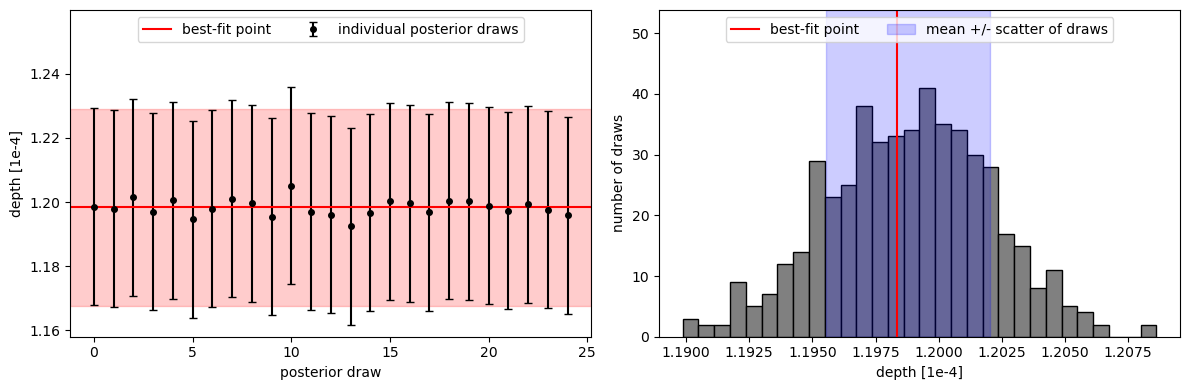

In [29]:
# TASK 4a: DOES THE DEPTH DEPEND ON WHICH POINT OF THE POSTERIOR

rng = np.random.default_rng(2024)
ndraw = 500
draw_idx = rng.choice(len(thetachainburnt), size=ndraw, replace=False)
draws = thetachainburnt[draw_idx]

draw_depth = np.zeros(ndraw)
draw_err = np.zeros(ndraw)
for k, theta_k in enumerate(draws):
    mod_k = model(time, theta_k)
    draw_depth[k], draw_err[k] = measure_depth(flux/mod_k, fluxerr/mod_k, intransit, outtransit)[:2]

depth_post = np.mean(draw_depth)
depth_scatter = np.std(draw_depth)                 
depth_staterr = np.mean(draw_err)                 
depth_total_err = np.sqrt(depth_staterr**2 + depth_scatter**2)

print('Depth at best-fit point            = %.4e +/- %.1e' % (depth, deptherr))
print('Depth averaged over %d draws      = %.4e' % (ndraw, depth_post))
print('  range over draws                 = %.4e to %.4e' % (draw_depth.min(), draw_depth.max()))
print('  scatter from detrending          = %.1e' % depth_scatter)
print('  photon-noise error               = %.1e' % depth_staterr)
print('  scatter / photon-noise error     = %.3f' % (depth_scatter/depth_staterr))
print('Depth incl. detrending uncertainty = %.4e +/- %.1e' % (depth_post, depth_total_err))

%matplotlib inline

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
u = 1e-4                                           # plot the depths in units of 1e-4

nshow = 25
ax[0].errorbar(np.arange(nshow), draw_depth[:nshow]/u, yerr=draw_err[:nshow]/u, fmt='ko', capsize=3, ms=4,
               label='individual posterior draws')
ax[0].axhline(depth/u, color='r', label='best-fit point')
ax[0].axhspan((depth-deptherr)/u, (depth+deptherr)/u, color='r', alpha=0.2)
ax[0].set_xlabel('posterior draw')
ax[0].set_ylabel('depth [1e-4]')
lo, hi = ax[0].get_ylim()
ax[0].set_ylim(lo, hi + 0.25*(hi-lo))              
ax[0].legend(loc='upper center', ncol=2)

# Right: distribution of the depth over all the draws
ax[1].hist(draw_depth/u, bins=30, color='grey', edgecolor='k')
ax[1].axvline(depth/u, color='r', label='best-fit point')
ax[1].axvspan((depth_post-depth_scatter)/u, (depth_post+depth_scatter)/u, color='b', alpha=0.2,
              label='mean +/- scatter of draws')
ax[1].set_xlabel('depth [1e-4]')
ax[1].set_ylabel('number of draws')
lo, hi = ax[1].get_ylim()
ax[1].set_ylim(lo, hi + 0.25*(hi-lo))
ax[1].legend(loc='upper center', ncol=2)
plt.tight_layout()
plt.show()


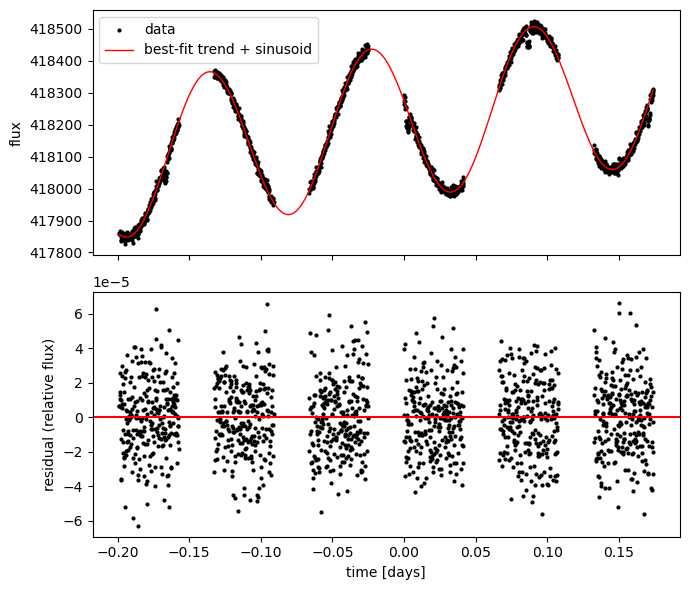

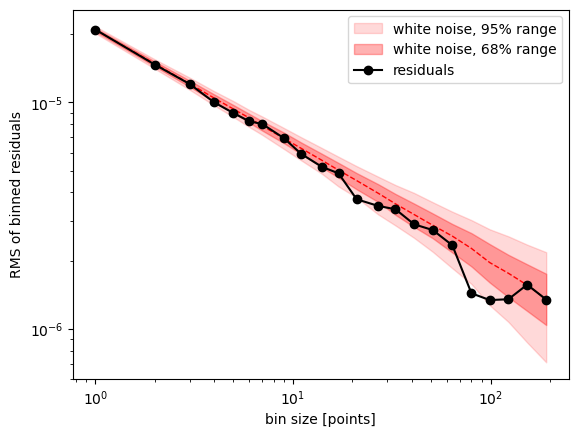

20 of 22 bin sizes lie inside the 95% white-noise range, 15 inside the 68% range
bin sizes ABOVE the 95% range (excess red noise): []
bin sizes BELOW the 95% range: [21 80]


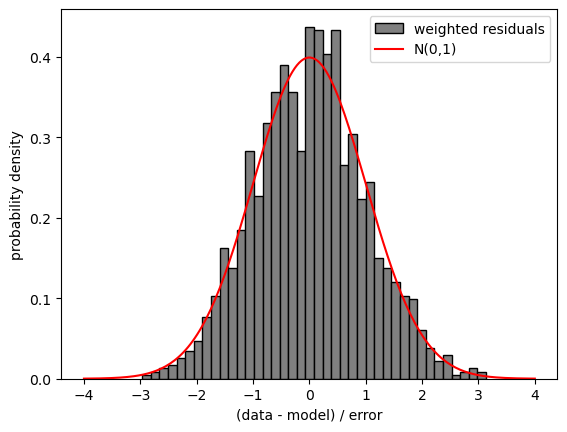

weighted residuals: mean = 0.000, std = 0.989


In [30]:
%matplotlib inline

# Residuals of the full model
transit_model = np.where(intransit, F_in, F_out)
resid = norm/transit_model - 1.0                
wresid = (norm - transit_model)/normerr          

#model and residuals 
fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax[0].scatter(data2[:,0], data2[:,1], color='k', s=4, label='data')
densetimes = np.arange(data2[0,0], data2[len(data2)-1,0], cadence)
ax[0].plot(densetimes, model(densetimes, thetabest), color='r', lw=1, label='best-fit trend + sinusoid')
ax[0].set_ylabel('flux')
ax[0].legend()
ax[1].scatter(data2[:,0], resid, color='k', s=4)
ax[1].axhline(0, color='r')
ax[1].set_xlabel('time [days]')
ax[1].set_ylabel('residual (relative flux)')
plt.tight_layout()
plt.show()

#RMS vs bin size
binsizes = np.unique(np.round(np.logspace(0, np.log10(len(resid)//8), 25)).astype(int))
rms = []
for N in binsizes:
    M = len(resid)//N                                  
    binned = resid[:M*N].reshape(M, N).mean(axis=1)
    rms.append(np.std(binned))
rms = np.array(rms)

# White-noise expectation as a shaded range simulate many white-noise series
nsim = 1000
rng = np.random.default_rng(1)
sims = np.zeros((nsim, len(binsizes)))
for k, N in enumerate(binsizes):
    M = len(resid)//N
    white = rng.normal(0.0, rms[0], size=(nsim, M, N)).mean(axis=2)
    sims[:, k] = np.std(white, axis=1)
lo68, hi68 = np.percentile(sims, [16, 84], axis=0)
lo95, hi95 = np.percentile(sims, [2.5, 97.5], axis=0)

plt.fill_between(binsizes, lo95, hi95, color='r', alpha=0.15, label='white noise, 95% range')
plt.fill_between(binsizes, lo68, hi68, color='r', alpha=0.30, label='white noise, 68% range')
plt.loglog(binsizes, np.median(sims, axis=0), 'r--', lw=1)
plt.loglog(binsizes, rms, 'ko-', label='residuals')
plt.xlabel('bin size [points]')
plt.ylabel('RMS of binned residuals')
plt.legend()
plt.show()
n95 = np.sum((rms >= lo95) & (rms <= hi95))
n68 = np.sum((rms >= lo68) & (rms <= hi68))
print('%d of %d bin sizes lie inside the 95%% white-noise range, %d inside the 68%% range' % (n95, len(rms), n68))
print('bin sizes ABOVE the 95%% range (excess red noise): %s' % binsizes[rms > hi95])
print('bin sizes BELOW the 95%% range: %s' % binsizes[rms < lo95])

#Weighted residuals histogram
plt.hist(wresid, bins=40, density=True, color='grey', edgecolor='k', label='weighted residuals')
x = np.linspace(-4, 4, 200)
plt.plot(x, np.exp(-0.5*x**2)/np.sqrt(2*np.pi), 'r', label='N(0,1)')
plt.xlabel('(data - model) / error')
plt.ylabel('probability density')
plt.legend()
plt.show()
print('weighted residuals: mean = %.3f, std = %.3f' % (wresid.mean(), wresid.std()))

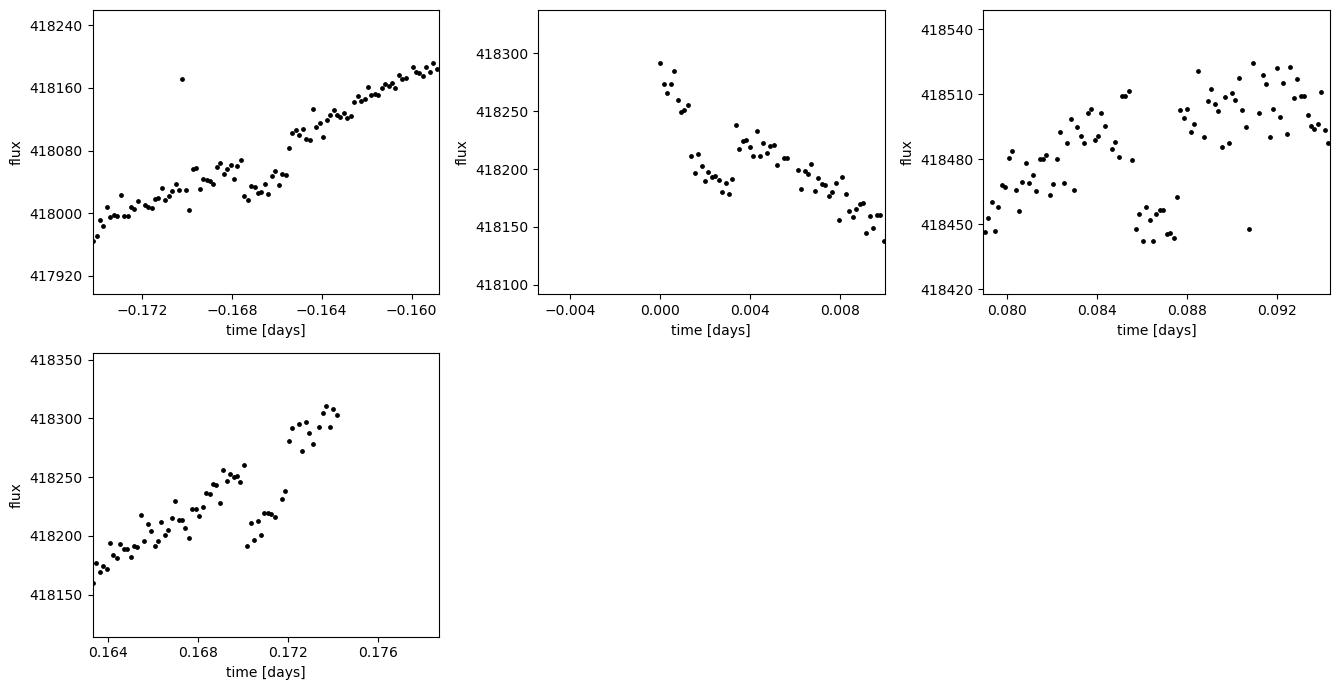

In [35]:
%matplotlib inline
from matplotlib.ticker import MaxNLocator

# Zoom in on each transit
t_mid = t0 - tpivot
n_all = np.arange(np.floor((time.min()-t_mid)/Ptran), np.ceil((time.max()-t_mid)/Ptran)+1)
centres = t_mid + n_all*Ptran
half = 4.0*dur   # half-width of each zoom window
centres = [tc for tc in centres if np.sum(np.abs(data2[:,0]-tc) < half) > 5]   

ncols = 3
nrows = int(np.ceil(len(centres)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.5*nrows), squeeze=False)
for ax, tc in zip(axes.flat, centres):
    g = np.abs(data2[:,0]-tc) < half
    b = np.abs(baddata[:,0]-tc) < half
    ax.scatter(data2[g,0], data2[g,1], color='k', s=6)
    ax.scatter(baddata[b,0], baddata[b,1], color='k', s=6)
    lo, hi = data2[g,1].min(), data2[g,1].max()
    pad = 0.3*(hi-lo)
    ax.set_xlim(tc-half, tc+half)
    ax.set_ylim(lo-pad, hi+pad)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))   
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_xlabel('time [days]')
    ax.set_ylabel('flux')
for ax in axes.flat[len(centres):]:
    ax.axis('off')
plt.tight_layout()
plt.show()